# Generating graphene monolayers

Pristine graphene sheets for molecular-dynamics models, with armchair and zigzag orientations.

## Lattice and sheet size

$$L_{\mathrm{AC}}=3b,\qquad L_{\mathrm{ZZ}}=\sqrt{3}b,\qquad N=4n_xn_y.$$

Complete rectangular cells keep the sheet periodic. The actual dimensions are listed below.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle
from scipy.spatial import cKDTree
from IPython.display import display

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#91a5ae", "axes.labelcolor": "#233744",
    "text.color": "#233744", "figure.facecolor": "white", "svg.fonttype": "none",
})
Path("figures").mkdir(exist_ok=True)
Path("data").mkdir(exist_ok=True)

bond = 1.396
target = np.array([350.0, 350.0])
z_bounds = (-10.0, 10.0)
species = {1: ("C", "#355463")}
masses = {1: 12.01}

In [2]:
def build_sheet(direction, target, bond):
    cell = np.array([3 * bond, np.sqrt(3) * bond])
    basis = np.array([[bond, cell[1] / 4], [2 * bond, cell[1] / 4],
                      [bond / 2, 3 * cell[1] / 4], [2.5 * bond, 3 * cell[1] / 4]])
    if direction == "ZZ":
        cell, basis = cell[::-1], basis[:, ::-1]
    elif direction != "AC":
        raise ValueError("Direction must be AC or ZZ")
    if np.any(np.asarray(target) <= 0) or bond <= 0:
        raise ValueError("Target lengths and bond spacing must be positive")
    repeats = np.floor(np.asarray(target) / cell).astype(int) + 1
    if np.any(repeats < 1):
        raise ValueError("The target must contain at least one complete cell")
    nx, ny = repeats
    ix, iy = np.meshgrid(np.arange(nx), np.arange(ny))
    shifts = np.c_[ix.ravel() * cell[0], iy.ravel() * cell[1]]
    xy = (shifts[:, None, :] + basis[None, :, :]).reshape(-1, 2)
    coordinates = np.c_[xy, np.zeros(len(xy))]
    types = np.tile([1, 1, 1, 1], nx * ny)
    return {"coordinates": coordinates, "types": types, "box": repeats * cell,
            "cell": cell, "repeats": repeats}

sheets = {direction: build_sheet(direction, target, bond) for direction in ["AC", "ZZ"]}

## Checking the periodic lattice

Three nearest neighbours per atom are checked across periodic x and y boundaries.

In [3]:
rows = []
for direction, sheet in sheets.items():
    xy, kinds, box = sheet["coordinates"][:, :2], sheet["types"], sheet["box"]
    assert np.all(xy > 0) and np.all(xy < box)
    assert len(xy) == 4 * np.prod(sheet["repeats"])
    distances, neighbors = cKDTree(xy, boxsize=box).query(xy, k=5)
    assert np.allclose(distances[:, 1:4], bond, atol=1e-9)
    assert np.all(distances[:, 4] > 1.05 * bond)
    assert np.all(kinds == 1)
    rows.append({"x direction": direction, "cells x": sheet["repeats"][0],
                 "cells y": sheet["repeats"][1], "atoms": len(xy),
                 "Lx (nm)": box[0] / 10, "Ly (nm)": box[1] / 10,
                 "nearest neighbours": 3})
summary = pd.DataFrame(rows)
display(summary.round({"Lx (nm)": 4, "Ly (nm)": 4}))

,x direction,cells x,cells y,atoms,Lx (nm),Ly (nm),nearest neighbours
0,AC,84,145,48720,35.1792,35.0602,3
1,ZZ,145,84,48720,35.0602,35.1792,3


## Sheet geometry

The full sheet is shown in nm and the local cell in Å.

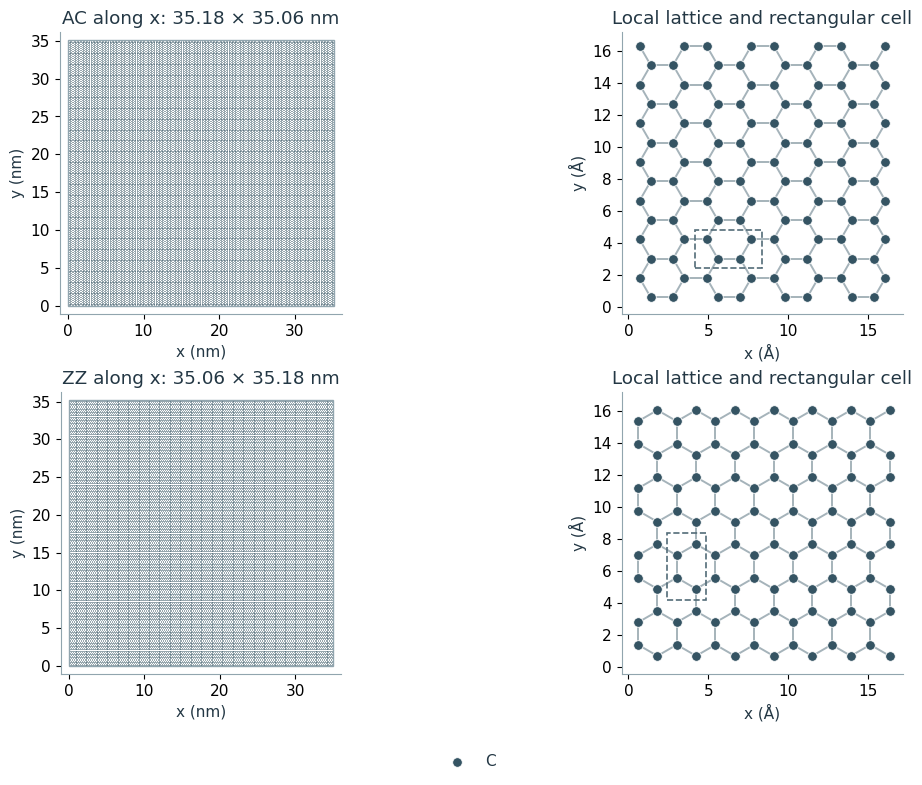

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11.2, 7.2), layout="constrained",
                         gridspec_kw={"width_ratios": [1.1, 1]})
for (direction, sheet), (overview, detail) in zip(sheets.items(), axes):
    xy, kinds, box, cell = sheet["coordinates"][:, :2], sheet["types"], sheet["box"], sheet["cell"]
    for kind, (name, color) in species.items():
        selected = kinds == kind
        overview.scatter(xy[selected, 0] / 10, xy[selected, 1] / 10, s=0.2,
                         c=color, linewidths=0, rasterized=True)
    overview.add_patch(Rectangle((0, 0), * (box / 10), fill=False, ec="#91a5ae", lw=1))
    overview.set(xlabel="x (nm)", ylabel="y (nm)", aspect="equal",
                 title=f"{direction} along x: {box[0] / 10:.2f} × {box[1] / 10:.2f} nm")
    overview.set_xlim(-0.03 * box[0] / 10, 1.03 * box[0] / 10)
    overview.set_ylim(-0.03 * box[1] / 10, 1.03 * box[1] / 10)

    window = 4 * max(cell)
    local = (xy[:, 0] < window) & (xy[:, 1] < window)
    points, local_types = xy[local], kinds[local]
    pairs = np.array(sorted(cKDTree(points).query_pairs(1.05 * bond)))
    detail.add_collection(LineCollection(points[pairs], colors="#a5b3ba", linewidths=1.4, zorder=1))
    for kind, (name, color) in species.items():
        selected = local_types == kind
        detail.scatter(points[selected, 0], points[selected, 1], s=48, c=color,
                       edgecolors="white", linewidths=0.6, label=name, zorder=2)
    detail.add_patch(Rectangle((cell[0], cell[1]), *cell, fill=False,
                              ec="#536c78", lw=1.2, ls="--", zorder=3))
    detail.set(xlabel="x (Å)", ylabel="y (Å)", aspect="equal", title="Local lattice and rectangular cell",
               xlim=(-0.3 * bond, window + 0.3 * bond),
               ylim=(-0.3 * bond, window + 0.3 * bond))
handles, labels = axes[0, 1].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="upper center",
           bbox_to_anchor=(0.5, -0.02), ncol=len(species))
fig.savefig("figures/graphene_monolayers.png", dpi=180, bbox_inches="tight")
fig.savefig("figures/graphene_monolayers.svg", bbox_inches="tight")
plt.show()

## LAMMPS data files

Planar coordinates are exported with `Atoms # atomic`. Type 1 is carbon; the z box is 20 Å. The z box provides vacuum spacing.

In [5]:
def write_data(path, sheet):
    xyz, kinds = sheet["coordinates"], sheet["types"]
    Lx, Ly = sheet["box"]
    with path.open("w", encoding="ascii") as f:
        f.write("Graphene monolayer geometry\n\n")
        f.write(f"{len(xyz)} atoms\n{len(masses)} atom types\n\n")
        f.write(f"0.0 {Lx:.12f} xlo xhi\n0.0 {Ly:.12f} ylo yhi\n")
        f.write(f"{z_bounds[0]:.12f} {z_bounds[1]:.12f} zlo zhi\n\nMasses\n\n")
        for kind, mass in masses.items():
            f.write(f"{kind} {mass:.6f}\n")
        f.write("\nAtoms # atomic\n\n")
        for atom_id, (kind, position) in enumerate(zip(kinds, xyz), 1):
            x, y, z = position
            f.write(f"{atom_id} {kind} {x:.12f} {y:.12f} {z:.12f}\n")
    return path

exports = [write_data(Path("data") / f"graphene_{direction}.data", sheet)
           for direction, sheet in sheets.items()]

for path, sheet in zip(exports, sheets.values()):
    lines = path.read_text(encoding="ascii").splitlines()
    start = lines.index("Atoms # atomic") + 2
    stored = np.loadtxt(lines[start:])
    assert len(stored) == len(sheet["types"])
    assert np.array_equal(stored[:, 0], np.arange(1, len(stored) + 1))
    assert np.array_equal(stored[:, 1], sheet["types"])
    assert np.allclose(stored[:, 2:], sheet["coordinates"], atol=1e-11, rtol=0)
display(pd.DataFrame({"data file": [p.as_posix() for p in exports],
                      "atoms written": [len(s["types"]) for s in sheets.values()]}))

,data file,atoms written
0,data/graphene_AC.data,48720
1,data/graphene_ZZ.data,48720
